# Model 1: Ordinary Least Squares (OLS) Linear Regression

This notebook estimates the parametric benchmark linear model fitting implied volatility as a function of log-moneyness m and time to maturity T: sigma_IV = beta_0 + beta_1 * m + beta_2 * T. Global metrics, 5x5 moneyness-maturity error grids, residual distributions, and 3D volatility surfaces are generated.

**Author:** Sérgio da Cunha Sobral
**Degree:** Master in Financial Mathematics (ISCTE-IUL)
**Supervisor:** Prof.ª Doutora Diana Mendes


### 1. Library Imports


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.linear_model import LinearRegression
import os, json, joblib
from datetime import datetime

### 2. Core Paths & Configuration


In [14]:
# Core Paths and Configuration
DIR_TRATADOS = "02_data/processed/"
DIR_RESULTADOS = "04_outputs/03_models_metadata/01_model_ols/"
DIR_GRAFICOS = "04_outputs/01_figures/04_model_ols/"
DIR_TABELAS = "04_outputs/02_tables/01_model_ols/"

# Ensure output directories exist
os.makedirs(DIR_GRAFICOS, exist_ok=True)
os.makedirs(DIR_RESULTADOS, exist_ok=True)
os.makedirs(DIR_TABELAS, exist_ok=True)

# Input data splits
path_universe        = os.path.join(DIR_TRATADOS, "Universo_Modelizacao_v1.00.parquet")
ficheiro_universo = path_universe
path_inner_train     = os.path.join(DIR_TRATADOS, "df_inner_train.parquet")
ficheiro_inner_train = path_inner_train
path_inner_tunning   = os.path.join(DIR_TRATADOS, "df_inner_tunning.parquet")
ficheiro_inner_tunning = path_inner_tunning
path_train_full      = os.path.join(DIR_TRATADOS, "df_train_full.parquet")
ficheiro_train_full = path_train_full
path_test_puro       = os.path.join(DIR_TRATADOS, "df_test_puro.parquet")
ficheiro_test_puro = path_test_puro

# Config
FEATURES = ("log_moneyness", "T")
TARGET = "iv_teorica"

# Model and metadata paths
MODEL_PATH_INNER = os.path.join(DIR_RESULTADOS, "01. OLS_model_inner.joblib")
META_PATH_INNER  = os.path.join(DIR_RESULTADOS, "01. OLS_model_inner.meta.json")

MODEL_PATH_FINAL = os.path.join(DIR_RESULTADOS, "01. OLS_model_final.joblib")
META_PATH_FINAL  = os.path.join(DIR_RESULTADOS, "01. OLS_model_final.meta.json")

### 3. Load Auxiliary Utilities


Palete de Cores:
azul1: #11469b
azul2: #2063c0
azul3: #5a90e7
cinza1: #777777
cinza2: #AAAAAA
cinza3: #bbbbbb
preto: #000000
branco: #ffffff

Estilos de Linha:
contínua: -
tracejada: --
ponto-traço: -.
pontilhada: :
contínua2: -
tracejada2: --
ponto-traço2: -.
pontilhada2: :


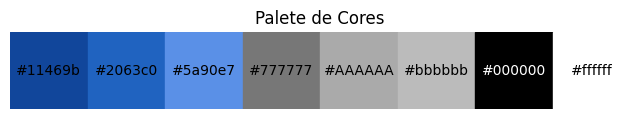

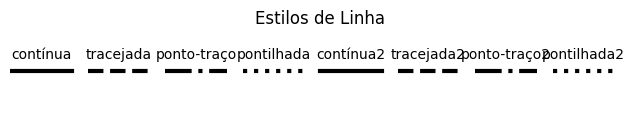

In [15]:
%run "03_notebooks/00_utils/01_auxiliary_functions.ipynb"

# Preview loaded color palette and line styles
if 'mostrar_cores' in globals() and 'PALETA_CORES' in globals():
    show_colors(COLOR_PALETTE)
if 'mostrar_estilos' in globals() and 'ESTILOS_LINHA' in globals():
    show_line_styles(LINE_STYLES)

### 4. Data Ingestion (Train, Tuning, and Test Splits)


In [16]:
# Load parquet dataset splits
df_inner_train = pd.read_parquet(path_inner_train)
df_inner_tunning = pd.read_parquet(path_inner_tunning)
df_train_full = pd.read_parquet(path_train_full)
df_test_puro = pd.read_parquet(path_test_puro)

# Initial verification of split dimensions
df_inner_train.shape, df_inner_tunning.shape, df_train_full.shape, df_test_puro.shape

((5970843, 11), (1534395, 11), (7505238, 11), (1292514, 11))

In [17]:
df_test_puro["iv_teorica"].describe()

count    1.292514e+06
mean     2.252946e-01
std      1.165048e-01
min      4.770584e-02
25%      1.460838e-01
50%      1.948600e-01
75%      2.698762e-01
max      1.982452e+00
Name: iv_teorica, dtype: float64

### 5. Modeling Setup & Pre-estimation Checks


In [18]:
# ──────────────────────────────────────────────────────────────────────────────
# Helpers
def _basic_checks(df: pd.DataFrame, features, target):
    cols_necessarias = list(features) + [target]
    em_falta = [c for c in cols_necessarias if c not in df.columns]
    if missing_cols:
        raise ValueError(f"Missing required columns: {em_falta}")

    sub = df[cols_necessarias]
    nan_counts = sub.isna().sum()
    if nan_counts.any():
        detalhe = nan_counts[nan_counts > 0].to_dict()
        raise ValueError(f"NaNs detected in feature columns: {detalhe}")

    arr = sub.to_numpy(dtype=float)
    if not np.isfinite(arr).all():
        inf_detail = {}
        for c in cols_necessarias:
            v = df[c].to_numpy(dtype=float)
            inf_detail[c] = int(np.isinf(v).sum()) + int(np.isnan(v).sum())
        raise ValueError(f"Non-finite values detected: {inf_detail}")
    return sub


def train_ols(df: pd.DataFrame, features=FEATURES, target=TARGET):
    sub = _basic_checks(df, features, target)
    X = sub[list(features)].to_numpy(dtype=float)
    y = sub[target].to_numpy(dtype=float)

    model = LinearRegression()  # fit_intercept=True por defeito
    model.fit(X, y)

    meta = {
        "model_type": "OLS (sklearn LinearRegression)",
        "features": list(features),
        "target": target,
        "fit_intercept": True,
        "n_obs": int(X.shape[0]),
        "n_features": int(X.shape[1]),
        "intercept": float(model.intercept_),
        "coefs": {name: float(coef) for name, coef in zip(features, model.coef_)},
        "trained_at": datetime.utcnow().isoformat() + "Z",
        "date_min": str(df['quote_date'].min()) if 'quote_date' in df.columns else None,
        "date_max": str(df['quote_date'].max()) if 'quote_date' in df.columns else None,
    }
    # Appends prediction column ivs_modelo to original DataFrame
    df_out = df.copy()
    df_out["ivs_modelo"] = model.predict(X)
    return model, meta, df_out


def save_model(model, meta: dict, model_path: str, meta_path: str):
    joblib.dump(model, model_path)
    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)


def load_model(model_path: str, meta_path: str):
    model = joblib.load(model_path)
    meta = None
    if os.path.exists(meta_path):
        with open(meta_path, "r", encoding="utf-8") as f:
            meta = json.load(f)
    return model, meta


def apply_model(df: pd.DataFrame, model, features=FEATURES, pred_col="ivs_modelo"):
    # non-destructive: validates and appends prediction column
    cols = list(features)
    missing_cols = [c for c in cols if c not in df.columns]
    if missing_cols:
        raise ValueError(f"Missing required columns for model application: {em_falta}")

    X = df[cols].to_numpy(dtype=float)
    if not np.isfinite(X).all():
        raise ValueError("Non-finite values detected in feature matrix during inference.")

    y_hat = model.predict(X)
    df_out = df.copy()
    df_out[pred_col] = y_hat
    return df_out

### 6. In-Sample Training (inner_train)


In [19]:
# df_inner_train already loaded
model_inner, meta_inner, df_inner_train_pred = train_ols(df_inner_train, FEATURES, TARGET)
save_model(model_inner, meta_inner, MODEL_PATH_INNER, META_PATH_INNER)

print("=== OLS | Training (inner_train) ===")
print(f"- Observações: {meta_inner['n_obs']}")
print(f"- Intercepto: {meta_inner['intercept']:.8f}")
for k,v in meta_inner["coefs"].items():
    print(f"  • coef {k}: {v:.8f}")
print(f"- Model exported to: {MODEL_PATH_INNER}")
print(f"- Metadados guardados em: {META_PATH_INNER}")
print("===================================")

C:\Users\sergi\AppData\Local\Temp\ipykernel_7248\3035324085.py:42: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "trained_at": datetime.utcnow().isoformat() + "Z",


=== OLS | Treino (inner_train) ===
- Observações: 5970843
- Intercepto: 0.19420295
  • coef log_moneyness: -0.34814339
  • coef T: -0.02132640
- Modelo guardado em: 04. Resultados/01. Modelo #1 - OLS/01. OLS_model_inner.joblib
- Metadados guardados em: 04. Resultados/01. Modelo #1 - OLS/01. OLS_model_inner.meta.json


### 7. Hyperparameter Tuning & Validation (inner_tunning)


In [20]:
model_inner, meta_inner = load_model(MODEL_PATH_INNER, META_PATH_INNER)

# Prediction column name identifies source split
df_inner_tunning_pred = apply_model(
    df_inner_tunning, model_inner, FEATURES, pred_col="ivs_modelo"
)

# (optional) store/use this output in evaluation pipeline
# df_inner_tunning_pred.to_parquet(os.path.join(DIR_RESULTADOS, "inner_tunning_pred_ols.parquet"))
print("=== OLS | Application to inner_tunning (no retraining) ===")
print(f"- Rows: {len(df_inner_tunning_pred):,}")
print(f"- Prediction column created: 'ivs_modelo'")
print("=======================================================")

=== OLS | Aplicação em inner_tunning (sem retreino) ===
- Linhas: 1,534,395
- Coluna criada: 'ivs_modelo'


### 8. Final Full Retraining (train_full)


In [21]:
model_final, meta_final, df_train_full_pred = train_ols(df_train_full, FEATURES, TARGET)
save_model(model_final, meta_final, MODEL_PATH_FINAL, META_PATH_FINAL)

print("=== OLS | Retreino (train_full) → Modelo FINAL ===")
print(f"- Observações: {meta_final['n_obs']}")
print(f"- Intercepto: {meta_final['intercept']:.8f}")
for k,v in meta_final["coefs"].items():
    print(f"  • coef {k}: {v:.8f}")
print(f"- FINAL model exported to: {MODEL_PATH_FINAL}")
print(f"- Metadados guardados em: {META_PATH_FINAL}")
print("===================================================")

# Betas normalizados (standardized coefficients)
FEATURES_LIST = list(FEATURES)
X = df_train_full[FEATURES_LIST]
y = df_train_full[TARGET]

# Coeficientes normalizados
betas_std = model_final.coef_ * (X.std(ddof=0).to_numpy() / y.std(ddof=0))

# Convert to relative weights (share of total impact)
weights = np.abs(betas_std) / np.sum(np.abs(betas_std))

print("\n=== Standardized coefficients (β) and relative weights ===")
for name, b, w in zip(FEATURES_LIST, betas_std, weights):
    print(f"  • {name:<15}: β = {b: .4f}   |   weight = {w*100:5.2f}%")


C:\Users\sergi\AppData\Local\Temp\ipykernel_7248\3035324085.py:42: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "trained_at": datetime.utcnow().isoformat() + "Z",


=== OLS | Retreino (train_full) → Modelo FINAL ===
- Observações: 7505238
- Intercepto: 0.19244656
  • coef log_moneyness: -0.37352803
  • coef T: -0.03329979
- Modelo FINAL guardado em: 04. Resultados/01. Modelo #1 - OLS/01. OLS_model_final.joblib
- Metadados guardados em: 04. Resultados/01. Modelo #1 - OLS/01. OLS_model_final.meta.json

=== Coeficientes normalizados (β) e pesos relativos ===
  • log_moneyness  : β = -0.6259   |   weight = 91.04%
  • T              : β = -0.0616   |   weight =  8.96%


### 9. Out-of-Sample Evaluation (Pure Test Set - test_puro)


In [22]:
model_final, meta_final = load_model(MODEL_PATH_FINAL, META_PATH_FINAL)

df_test_puro_pred = apply_model(
    df_test_puro, model_final, FEATURES, pred_col="ivs_modelo"
)

# (opcional) persistir
# df_test_puro_pred.to_parquet(os.path.join(DIR_RESULTADOS, "test_puro_pred_ols.parquet"))

print("=== OLS | Application to test_puro (FINAL model) ===")
print(f"- Rows: {len(df_test_puro_pred):,}")
print(f"- Prediction column created: 'ivs_modelo'")
print("===================================================")

=== OLS | Aplicação ao test_puro (modelo FINAL) ===
- Linhas: 1,292,514
- Coluna criada: 'ivs_modelo'


### 10. Evaluation Metrics & 5×5 Moneyness-Maturity Bin Analysis


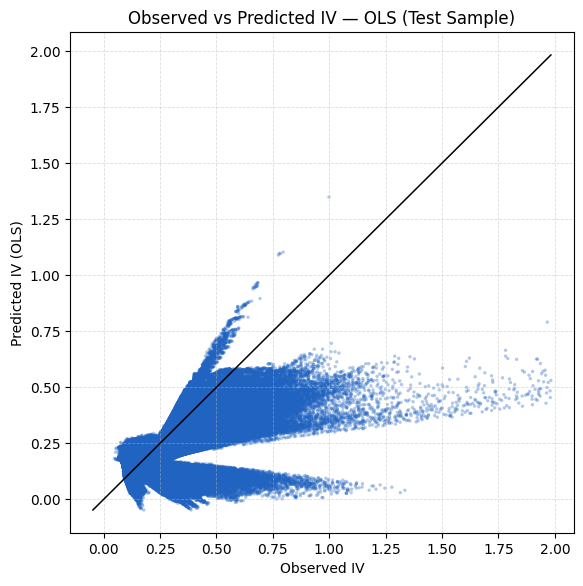

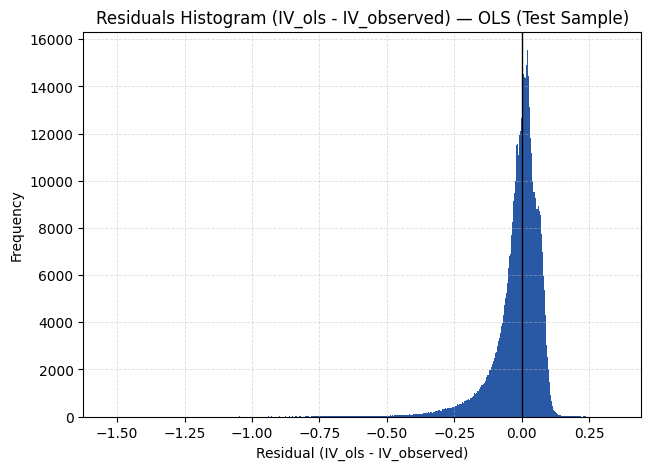

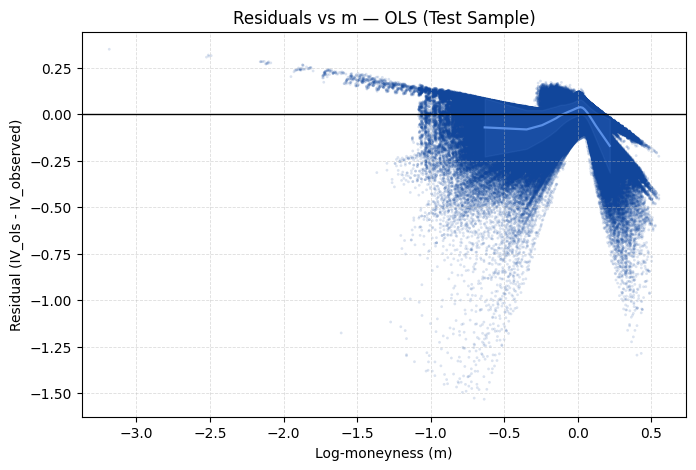

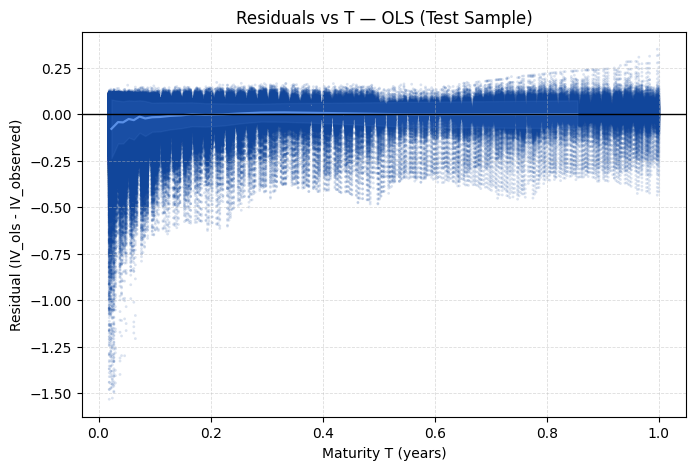

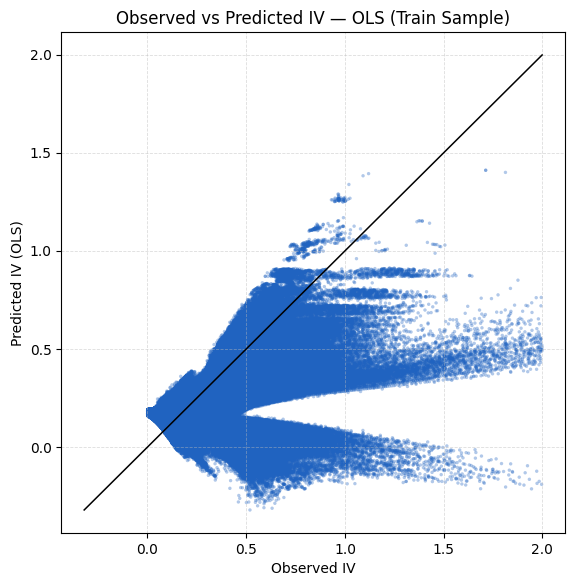

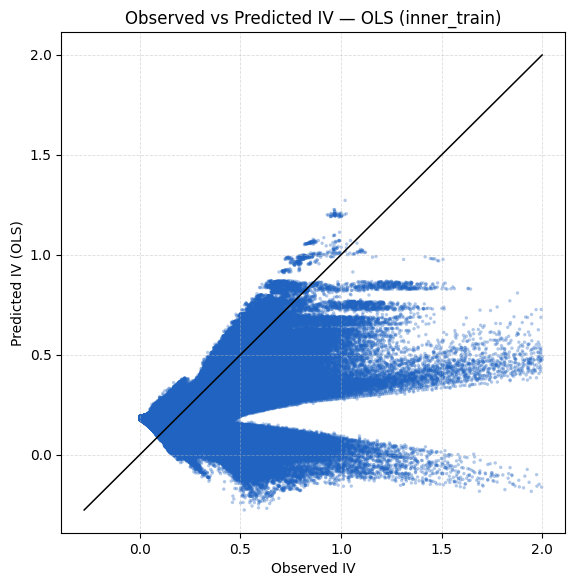

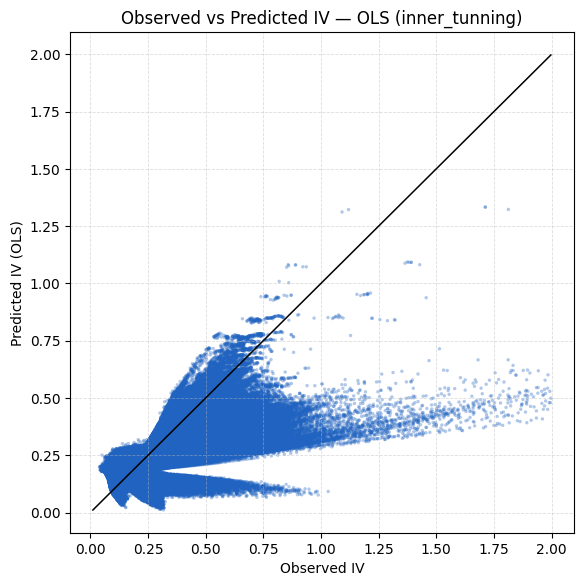

,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,OLS,test_puro,geral,train_full,1292514,0.089193,0.057087,0.039164,0.413900,-1.404004e-02
1,OLS,train_full,especifica,train_full,7505238,0.098052,0.065535,0.050726,0.383647,2.520572e-17
2,OLS,Test Sample,geral,train_full,1292514,0.089193,0.057087,0.039164,0.413900,-1.404004e-02
3,OLS,Train Sample,especifica,train_full,7505238,0.098052,0.065535,0.050726,0.383647,2.520572e-17
4,OLS,inner_train,especifica,inner_training,5970843,0.100203,0.067465,0.052647,0.353800,-2.437163e-17
5,OLS,inner_tunning,especifica,inner_training,1534395,0.090192,0.064024,0.053266,0.482026,1.122217e-02


,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,OLS,test_puro,geral,train_full,1292514,0.089193,0.057087,0.039164,0.413900,-1.404004e-02
1,OLS,train_full,especifica,train_full,7505238,0.098052,0.065535,0.050726,0.383647,2.520572e-17
2,OLS,Test Sample,geral,train_full,1292514,0.089193,0.057087,0.039164,0.413900,-1.404004e-02
3,OLS,Train Sample,especifica,train_full,7505238,0.098052,0.065535,0.050726,0.383647,2.520572e-17
4,OLS,inner_train,especifica,inner_training,5970843,0.100203,0.067465,0.052647,0.353800,-2.437163e-17


In [23]:
# --- Run model evaluation pipeline ---
res_ols = run_avaliacoes(
    df_inner_train=df_inner_train_pred,
    df_inner_tunning=df_inner_tunning_pred,
    df_train_full=df_train_full_pred,
    df_test_puro=df_test_puro_pred,
    model="OLS",
    DIR_TABELAS=DIR_TABELAS,
    DIR_GRAFICOS=DIR_GRAFICOS,
    scatter_mode="all",          # "all" | "subsample" | "hexbin"
    max_points_scatter=250_000,  # só usado se scatter_mode="subsample"
    dpi=160,
    display_in_notebook=True     # mostra gráficos + tabela no output do VS Code
)

# If tabular DataFrame is needed in variable:
res_ols["globais_df"].head()

### 11. 3D Volatility Surface & Residual Diagnostics


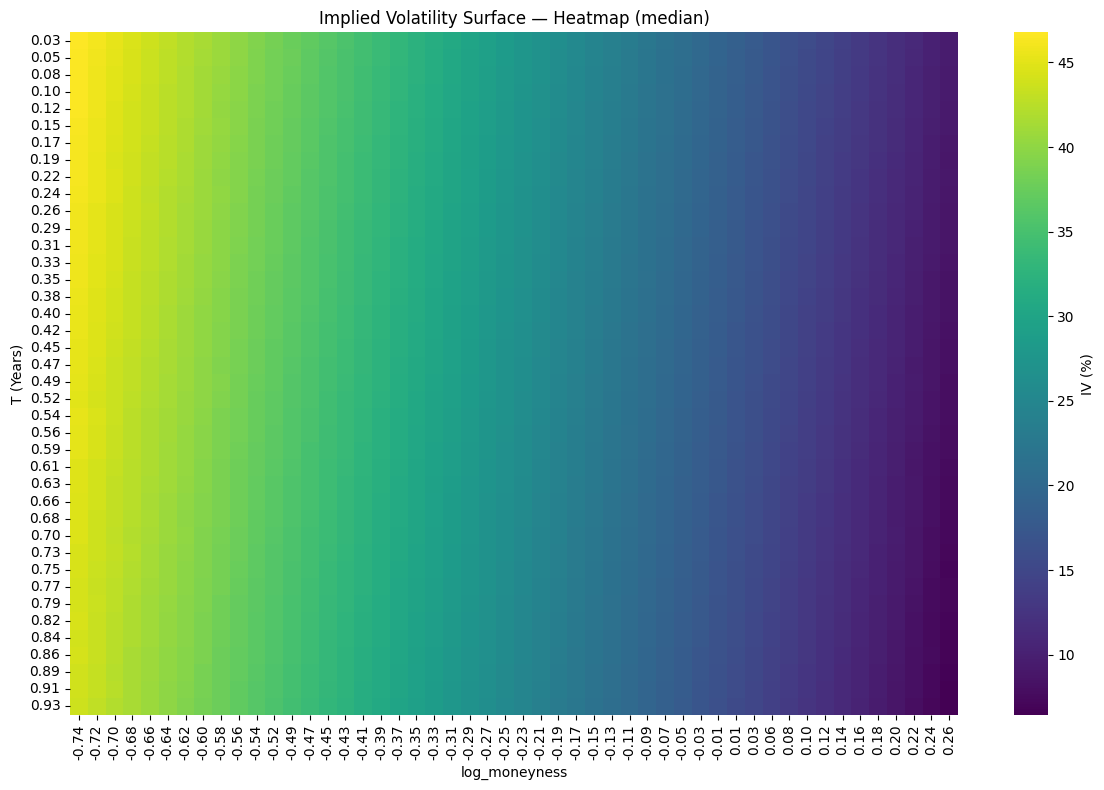

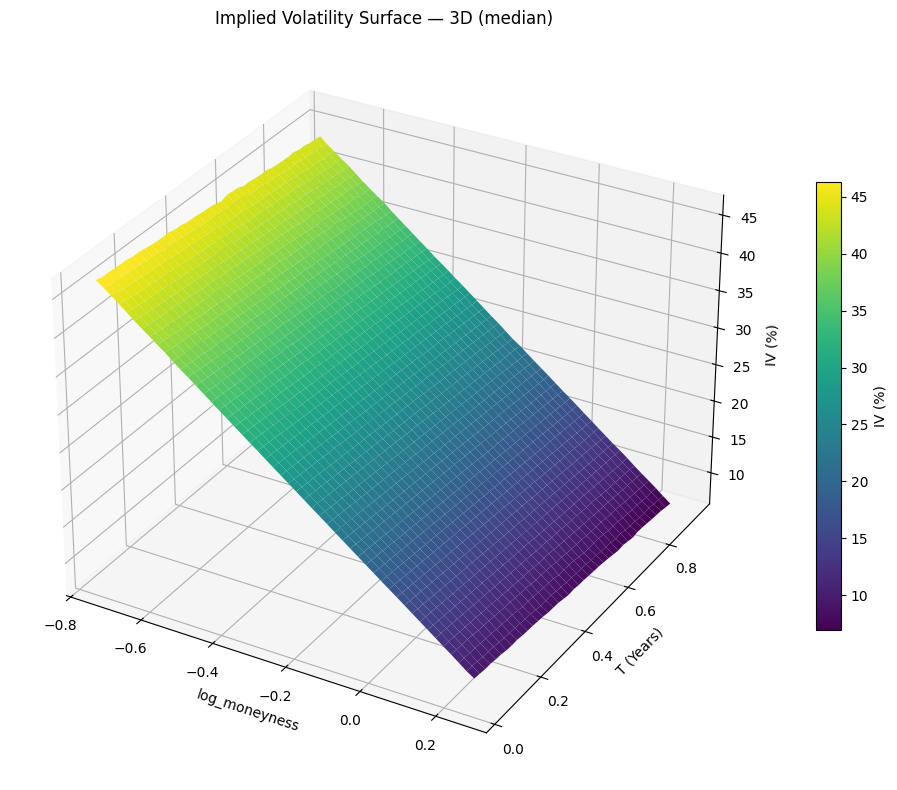

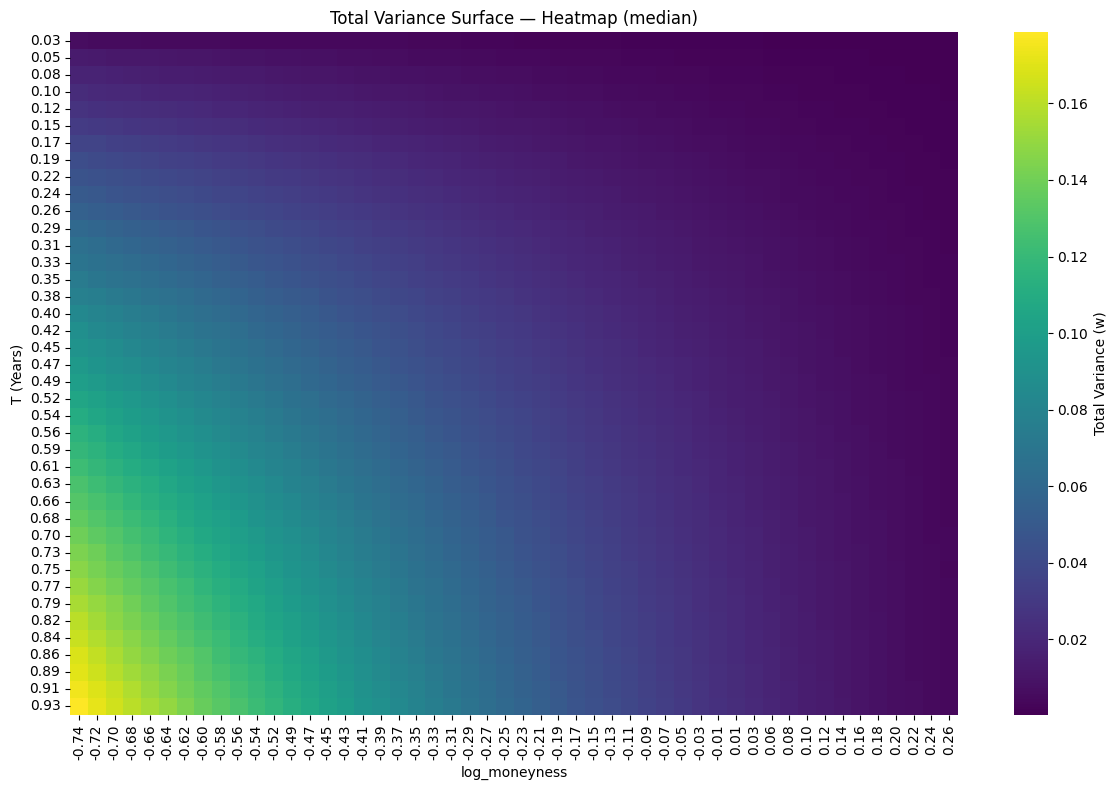

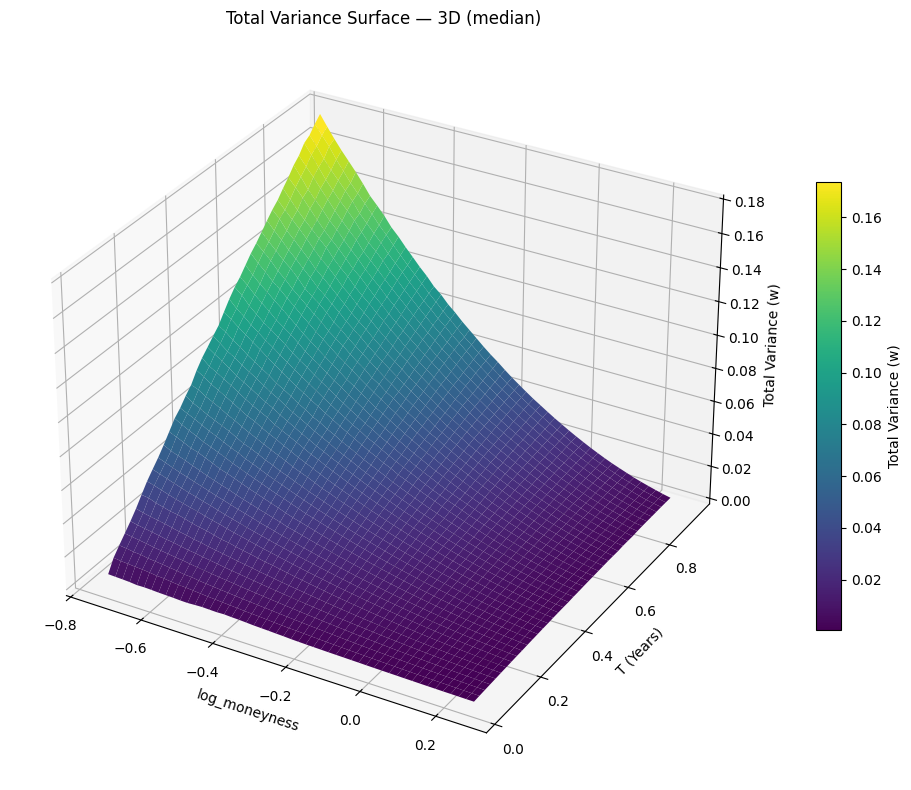

In [24]:
# 1) IVS e Superfícies de Variância do Modelo
plot_ivs_and_variance_surfaces(
    df_test_puro_pred,
    x_col="log_moneyness", y_col="T", z_col="ivs_modelo",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="OLS"
)